# EDA

53 anonymized features and a target. Task: Understand how the target depends on the features and pick a model with the lowest RMSE.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# show plain decimals instead of scientific notation (1e-14)
pd.set_option("display.float_format", "{:.6f}".format)

train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/hidden_test.csv")

print("train:", train.shape)
print("test: ", test.shape)

## 1. Overview

In [8]:
train.head()

,0,1,2,3,4,5,6,7,8,9,...,44,45,46,47,48,49,50,51,52,target
0,236,488,16,221,382,97,-4.472136,0.107472,0,132,...,13.340874,0.870542,1.962937,7.466666,11.547794,8.822916,9.046424,7.895535,11.010677,20.107472
1,386,206,357,232,1,198,7.810250,0.763713,1,143,...,12.484882,7.168680,2.885415,12.413973,10.260494,10.091351,9.270888,3.173994,13.921871,61.763713
2,429,49,481,111,111,146,8.602325,0.651162,1,430,...,14.030257,0.394970,8.160625,12.592059,8.937577,2.265191,11.255721,12.794841,12.080951,74.651162
3,414,350,481,370,208,158,8.306624,0.424645,1,340,...,2.789577,6.416708,10.549814,11.456437,6.468099,2.519049,0.258284,9.317696,5.383098,69.424645
4,318,359,20,218,317,301,8.124038,0.767304,1,212,...,1.886560,1.919999,2.268203,0.149421,4.105907,10.416291,6.816217,8.586960,4.512419,66.767304


In [9]:
print("Missing values in train:", train.isna().sum().sum())
print("Missing values in test: ", test.isna().sum().sum())
print("Duplicated rows in train:", train.duplicated().sum())
print()
print("Column types:")
print(train.dtypes.value_counts())

Missing values in train: 0
Missing values in test:  0
Duplicated rows in train: 0

Column types:
float64    43
int64      11
Name: count, dtype: int64


In [5]:
# Number of unique values per feature: helps to spot categorical / discrete features.
features = [c for c in train.columns if c != "target"]
train[features].nunique().sort_values()

8         2
6       199
2       500
0       500
3       500
4       500
5       500
1       500
12      500
9       500
10      500
11      500
7     90000
13    90000
14    90000
15    90000
16    90000
17    90000
18    90000
19    90000
20    90000
21    90000
22    90000
23    90000
24    90000
25    90000
26    90000
27    90000
28    90000
29    90000
30    90000
31    90000
32    90000
33    90000
34    90000
35    90000
36    90000
37    90000
38    90000
39    90000
40    90000
41    90000
42    90000
43    90000
44    90000
45    90000
46    90000
47    90000
48    90000
49    90000
50    90000
51    90000
52    90000
dtype: int64

## 2. Target distribution

count    90000.000000
mean        50.033981
std         28.897243
min          0.002634
25%         25.091903
50%         50.030705
75%         75.059454
max         99.999482
Name: target, dtype: float64


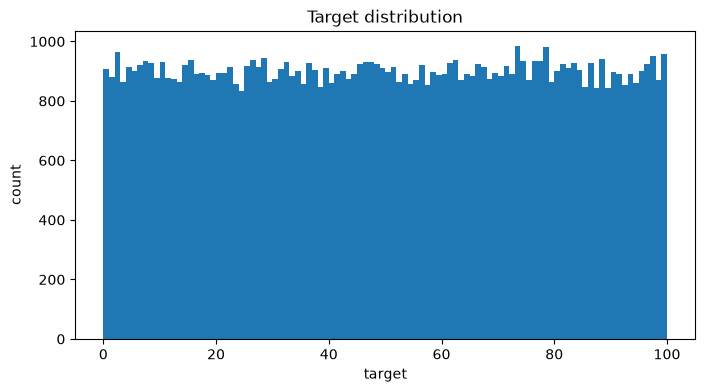

In [10]:
print(train["target"].describe())

plt.figure(figsize=(8, 4))
plt.hist(train["target"], bins=100)
plt.title("Target distribution")
plt.xlabel("target")
plt.ylabel("count")
plt.show()

## 3. Linear correlation with target

In [11]:
# Pearson correlation of every feature with the target, strongest first.
corr = train.corr()["target"].drop("target")
corr.abs().sort_values(ascending=False).head(10)

7     0.012103
40    0.007216
26    0.006370
39    0.006283
35    0.006267
1     0.005545
50    0.005243
31    0.005077
29    0.004785
51    0.004507
Name: target, dtype: float64

All correlations are close to zero, the highest is 0.012. That doesn't mean the features are useless, Pearson correlation only catches linear relationships. For example y = x² on a symmetric range has zero correlation with x. So look at scatter plots instead.

## 4. Target vs each feature

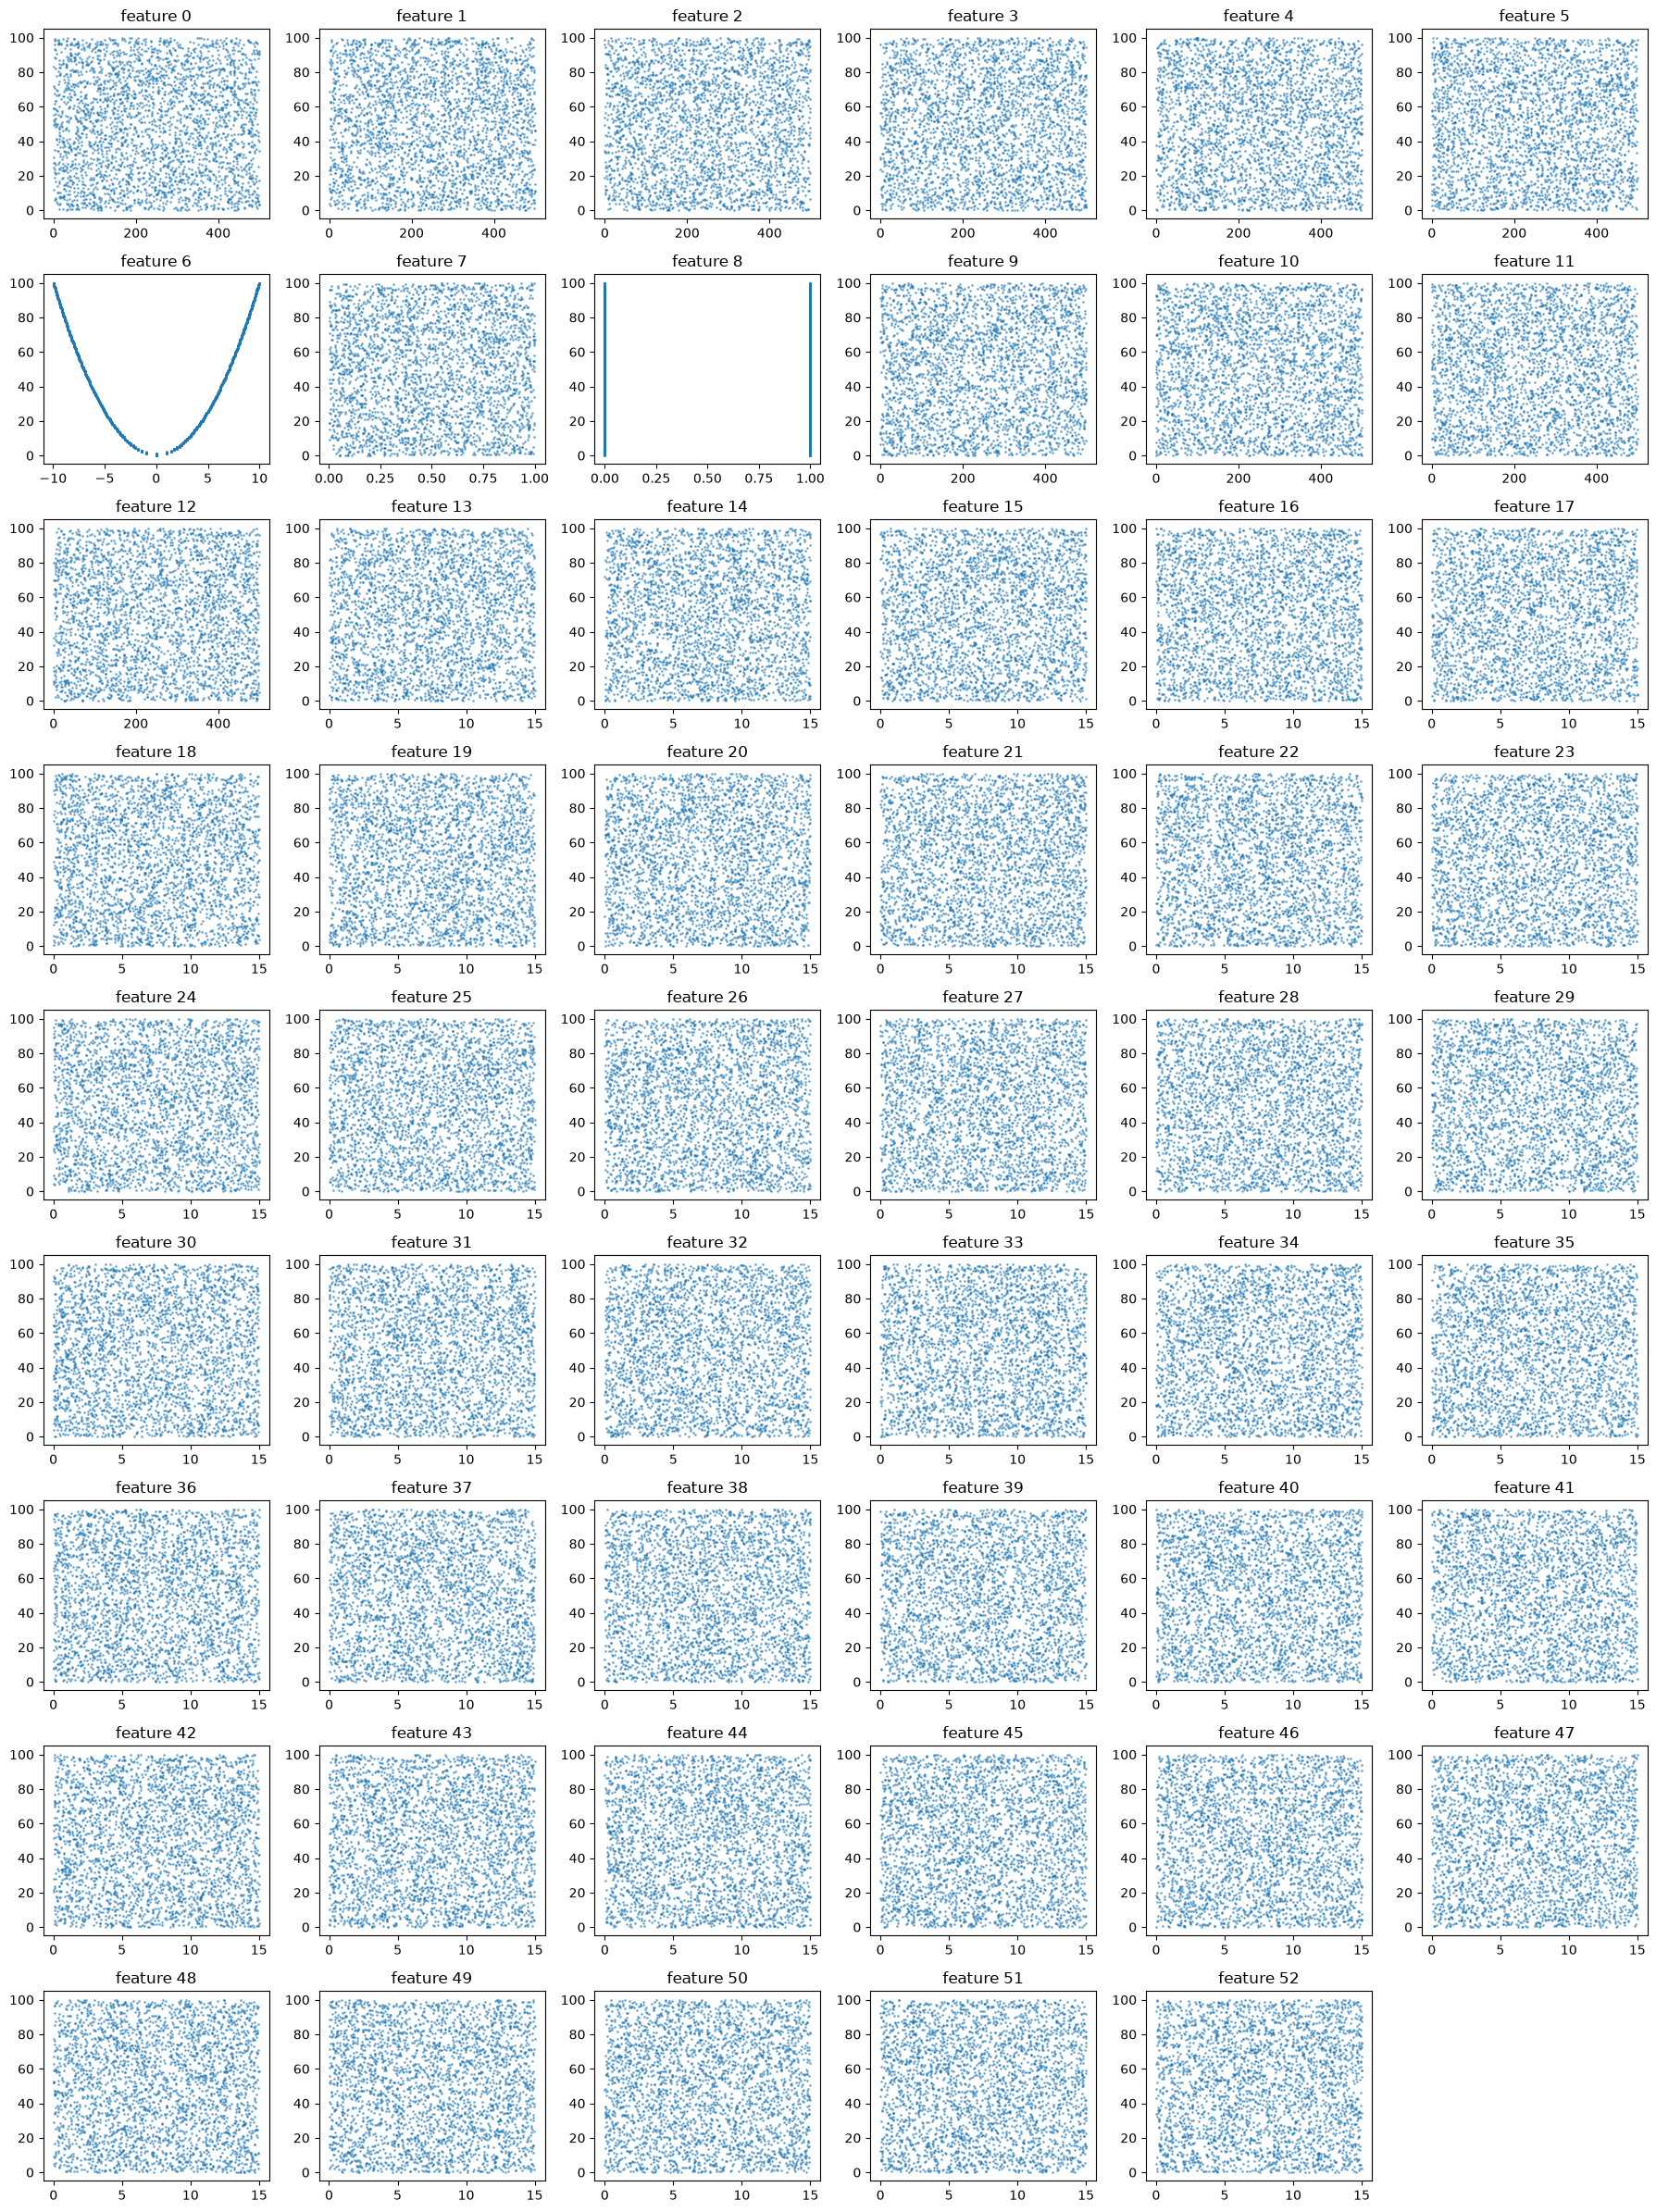

In [12]:
# Scatter plot of target vs every feature (on a random sample to keep it fast).
sample = train.sample(3000, random_state=42)

fig, axes = plt.subplots(9, 6, figsize=(18, 24))
for ax, col in zip(axes.flat, features):
    ax.scatter(sample[col], sample["target"], s=1, alpha=0.5)
    ax.set_title(f"feature {col}")
for ax in axes.flat[len(features):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

Feature 6 is clearly a parabola: it goes from -10 to 10 and the target from 0 to 100, so target ≈ feature_6². Feature 8 is binary, the two vertical lines just cover the whole target range, no relationship there. Everything else looks like noise.

The parabola is not a thin line but a band about 1 unit wide, so something else adds a value between 0 and 1.

## 5. What is left after feature_6²

count    90000.000000
mean         0.498548
std          0.288682
min          0.000014
25%          0.248932
50%          0.497136
75%          0.747513
max          0.999987
dtype: float64


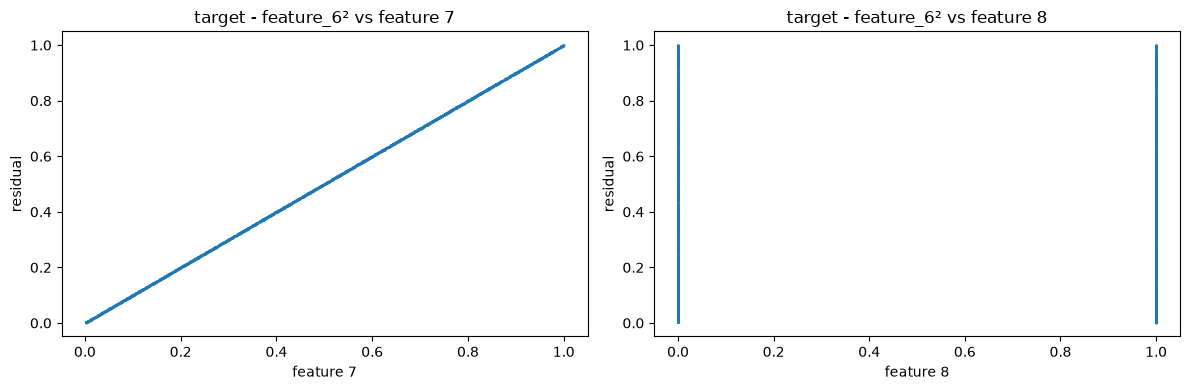

In [13]:
# What is left of the target after removing feature_6^2?
residual = train["target"] - train["6"] ** 2
print(residual.describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["7", "8"]):
    ax.scatter(sample[col], residual.loc[sample.index], s=1, alpha=0.5)
    ax.set_title(f"target - feature_6² vs feature {col}")
    ax.set_xlabel(f"feature {col}")
    ax.set_ylabel("residual")
plt.tight_layout()
plt.show()

In [29]:
# The residual should now depend on something linearly, so correlation works here.
# Correlation of the residual with every feature, strongest first:
train[features].corrwith(residual).abs().sort_values(ascending=False).head(5)

7    1.000000
51   0.008363
20   0.007655
9    0.007187
0    0.007174
dtype: float64

The residual is a straight line against feature 7, and nothing against feature 8. The correlation check says the same: the residual has correlation 1.0 with feature 7 and below 0.01 with everything else. So my hypothesis is:

target = feature_6² + feature_7

## 6. Checking the formula

In [30]:
prediction = train["6"] ** 2 + train["7"]
error = train["target"] - prediction

print(f"RMSE of the formula on train: {np.sqrt((error ** 2).mean()):.6f}")
print(f"Max absolute error:           {error.abs().max():.6f}")
print(f"Baseline RMSE (predict mean): {train['target'].std(ddof=0):.6f}")

RMSE of the formula on train: 0.000000
Max absolute error:           0.000000
Baseline RMSE (predict mean): 28.897082


The formula matches every row, RMSE is practically 0 (compared to 28.9 for always predicting the mean). The tiny error that is left is float rounding: feature 6 looks like square roots of integers (-4.472136 = -sqrt(20)), so squaring gives 20.000000000000004 instead of 20.

## 7. Train vs hidden_test

Before using the formula on the test set I want to make sure features 6 and 7 look the same there.

           train_6       test_6      train_7       test_7
count 90000.000000 10000.000000 90000.000000 10000.000000
mean     -0.011402    -0.079268     0.498548     0.505215
std       7.038171     7.032273     0.288682     0.285678
min      -9.949874    -9.949874     0.000014     0.000260
25%      -7.071068    -7.071068     0.248932     0.261199
50%       0.000000    -1.000000     0.497136     0.507519
75%       7.000000     7.071068     0.747513     0.750603
max       9.949874     9.949874     0.999987     0.999982


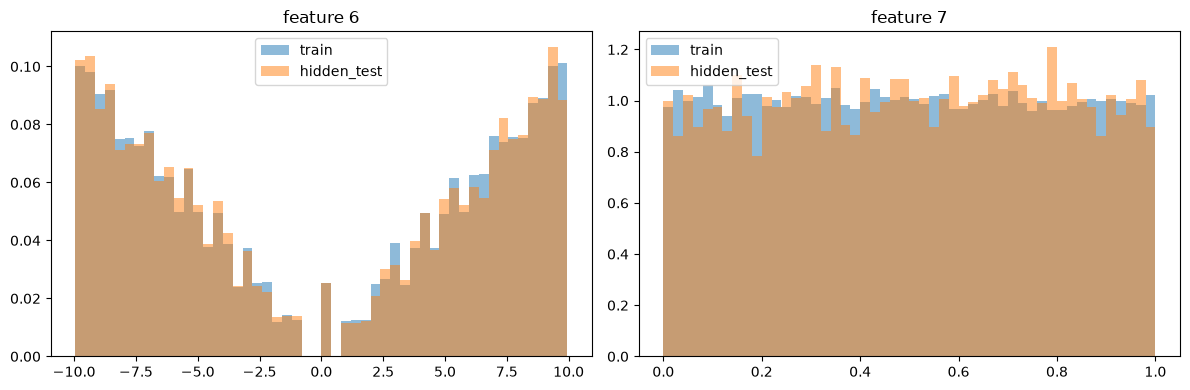

In [31]:
# Do features 6 and 7 in hidden_test cover the same range as in train?
print(pd.DataFrame({
    "train_6": train["6"].describe(),
    "test_6": test["6"].describe(),
    "train_7": train["7"].describe(),
    "test_7": test["7"].describe(),
}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["6", "7"]):
    ax.hist(train[col], bins=50, density=True, alpha=0.5, label="train")
    ax.hist(test[col], bins=50, density=True, alpha=0.5, label="hidden_test")
    ax.set_title(f"feature {col}")
    ax.legend()
plt.tight_layout()
plt.show()

Same ranges and same distributions in train and test, so the formula should work on the test set too.

The U-shape of feature 6 makes sense if it is ±sqrt(n) for n = 0..99: square roots get denser closer to 10, and there is nothing between sqrt(0) = 0 and sqrt(1) = 1.

## 8. Comparing models

I train on 80% of train.csv and check RMSE on the other 20%, which the models haven't seen.

In [32]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split

X = train.drop(columns="target")
y = train["target"]
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)


def engineer(df):
    """The two features found in the EDA."""
    return pd.DataFrame({"6_squared": df["6"] ** 2, "7": df["7"]})


results = {}

# 1. Always predict the mean of the training target.
results["Mean baseline"] = root_mean_squared_error(y_val, np.full(len(y_val), y_train.mean()))

# 2. Linear regression on all 53 raw features.
lin_raw = LinearRegression().fit(X_train, y_train)
results["Linear, 53 raw features"] = root_mean_squared_error(y_val, lin_raw.predict(X_val))

# 3. Random Forest on all 53 raw features (takes ~1 minute).
rf = RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42).fit(X_train, y_train)
results["Random Forest, 53 raw features"] = root_mean_squared_error(y_val, rf.predict(X_val))

# 4. Linear regression on the engineered features [6², 7].
lin_eng = LinearRegression().fit(engineer(X_train), y_train)
results["Linear, [6², 7]"] = root_mean_squared_error(y_val, lin_eng.predict(engineer(X_val)))

print(pd.Series(results, name="validation RMSE").to_string())
print()
print(f"Learned coefficients: 6_squared = {lin_eng.coef_[0]:.6f}, 7 = {lin_eng.coef_[1]:.6f}, intercept = {lin_eng.intercept_:.6f}")

Mean baseline                    29.003837
Linear, 53 raw features          29.015413
Random Forest, 53 raw features    0.003807
Linear, [6², 7]                   0.000000

Learned coefficients: 6_squared = 1.000000, 7 = 1.000000, intercept = 0.000000


In [33]:
# Which features did the Random Forest rely on? (independent check of the EDA findings)
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
importances.head(10)

6    0.999900
7    0.000100
16   0.000000
45   0.000000
25   0.000000
19   0.000000
36   0.000000
47   0.000000
29   0.000000
23   0.000000
dtype: float64

| Model | Validation RMSE |
|---|---|
| Mean baseline | 29.0 |
| Linear regression, 53 raw features | 29.0 |
| Random Forest, 53 raw features | 0.0038 |
| Linear regression, [6², 7] | ~0 |

Linear regression on raw features is no better than the mean. It can only fit a straight line, and the best straight line through a symmetric parabola is flat.

Random Forest does surprisingly well without any feature engineering. Feature 6 has only 199 values, so the trees can approximate the parabola with steps. Still not exact though.

Its feature importances agree with what I found: feature 6 gets 99.99%, feature 7 gets 0.01%, the rest is basically 0. Feature 7 is low only because it adds 0..1 to the target while feature_6² adds 0..100.

Linear regression on [6², 7] learns coefficients 1 and 1 with intercept 0, which is exactly the formula.

## Conclusion

target = feature_6² + feature_7, the other 51 features are noise.

I'm going with linear regression on [feature_6², feature_7]. It gives practically zero error, trains instantly, is easy to interpret, and the test set has the same feature distribution as train.